# How many of them could be the one?

The soul mate premise gives each person one possible partner in a pool of about 1.3 billion. The How
Couples Meet and Stay Together survey (HCMST) shows how many people actually have had a partner by each
age. This notebook asks what share of the people you talk to would have to be possible partners for the
two to match.

To get the data, read and accept the data use agreement on https://data.stanford.edu/hcmst2017, then
save `HCMST 2017 to 2022 small public version 2.2.dta` to `data/raw/`. The agreement asks you to tell
the HCMST contact person about your work and to cite the data.

Data citation: Rosenfeld, Michael J., Reuben J. Thomas, and Sonia Hausen. 2023. How Couples Meet and Stay
Together 2017-2020-2022 combined dataset. [Computer files]. Stanford, CA: Stanford University Libraries.
https://data.stanford.edu/hcmst2017

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm

from soulmates.france import load_diaries, load_france_days
from soulmates.hcmst import load_hcmst
from soulmates.match import build_flat_model, build_match_model, lifetime_curve, partner_chance
from soulmates.model import build_model

hcmst = load_hcmst("../data/raw/HCMST 2017 to 2022 small public version 2.2.dta")
bands = pd.cut(hcmst["age"], [17, 24, 29, 34, 39, 49, 60])
observed = hcmst.groupby(bands, observed=True).apply(lambda g: pd.Series({
    "people": len(g),
    "never had a partner": int((~g["ever_partnered"]).sum()),
    "ever, share": g["ever_partnered"].mean(),
    "ever, weighted share": np.average(g["ever_partnered"], weights=g["weight"]),
})).astype({"people": int, "never had a partner": int})
observed.round(3)

,people,never had a partner,"ever, share","ever, weighted share"
age,,,,
"(17, 24]",254,49,0.807,0.768
"(24, 29]",410,31,0.924,0.910
"(29, 34]",251,3,0.988,0.985
"(34, 39]",272,7,0.974,0.970
"(39, 49]",505,5,0.990,0.990
"(49, 60]",828,3,0.996,0.996


## People differ in how many others they meet

In the French survey every participant kept a diary on two days. If the number of new people only
depended on the day, the two counts would be unrelated. The cell looks at new people of any age first,
and then at new people within 5 years of the participant's age, which are fewer and noisier.

In [2]:
for label, window in [("new people of any age", 200), ("new people of your own age", 5)]:
    france = load_france_days("../data/raw/france2012", window=window)
    adults = france[france["age"].between(18, 60)]
    two_days = adults.pivot_table(index=["part_id", "wave"], columns="day", values="new_contacts").dropna()
    none_one_day = ((two_days[1] == 0).mean() + (two_days[2] == 0).mean()) / 2
    none_both = ((two_days[1] == 0) & (two_days[2] == 0)).mean()
    between = np.cov(two_days[1], two_days[2])[0, 1]  # how much of the spread stays with the person
    mean = two_days.to_numpy().mean()
    print(f"{label}: {len(two_days)} adults with two diary days, {mean:.2f} per day")
    print(f"  correlation between the two days: {two_days[1].corr(two_days[2]):.2f}")
    print(f"  nobody new on a day: {none_one_day:.1%}. On both days: {none_both:.1%}. If the days were unrelated: {none_one_day ** 2:.1%}")
    print(f"  spread of personal rates implied by the two days: k = {mean ** 2 / between:.2f}")

new people of any age: 661 adults with two diary days, 1.63 per day
  correlation between the two days: 0.40
  nobody new on a day: 57.6%. On both days: 39.6%. If the days were unrelated: 33.2%
  spread of personal rates implied by the two days: k = 0.60
new people of your own age: 661 adults with two diary days, 0.41 per day
  correlation between the two days: 0.06
  nobody new on a day: 80.6%. On both days: 68.2%. If the days were unrelated: 64.9%
  spread of personal rates implied by the two days: k = 1.62


A small k means that people differ a lot. The two days lie in the same survey wave, so they also share
what was going on in that person's life in those weeks. These values of k therefore overstate lasting
differences. They are a lower bound for k, and the partner model below estimates k from HCMST.

## New people met by each age

N(a) is the number of new people of your own age you have met and talked to from age 15 up to age a, in
a typical country. It comes from the contact model of notebook 02.

In [3]:
with build_model(load_diaries("../data/raw")):
    contacts = pm.sample(random_seed=2, progressbar=False)
curve = lifetime_curve(contacts.posterior, start_age=15)
print({age: round(curve[age]) for age in (18, 25, 40, 60)})

no part_age: 65 of 7290 rows (0.9%)
no dayofweek: 136 of 7290 rows (1.9%)
no frequency_multi: 1407 of 97904 rows (1.4%)


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu_pop, sigma_band, z, sigma_country, log_factor, beta_weekend, alpha, z_new, p_recog]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 52 seconds.


{18: 410, 25: 1748, 40: 4091, 60: 5783}


## The partner model

Each person you talk to is a possible partner with chance q. Each person meets their own number of
people: the average N(a) times a personal factor with mean 1. The number k says how much people differ.
A small k means large differences. The chance of having had a partner by age a is then
1 − (1 + θ × N(a) / k) ^ (−k), with θ = −log(1 − q).

The simpler model for comparison gives everyone exactly N(a) people.

In [4]:
with build_match_model(hcmst, curve):
    match = pm.sample(random_seed=2, target_accept=0.95, idata_kwargs={"log_likelihood": True})
with build_flat_model(hcmst, curve):
    flat = pm.sample(random_seed=2, idata_kwargs={"log_likelihood": True})
q, k = match.posterior["q"].values.ravel(), match.posterior["k"].values.ravel()
q_flat = flat.posterior["q"].values.ravel()
print(f"q: 1 in {1 / np.median(q):,.0f}, 94% interval 1 in {1 / np.percentile(q, 97):,.0f} to 1 in {1 / np.percentile(q, 3):,.0f}")
print(f"k: {np.median(k):.2f}, 94% interval {np.percentile(k, 3):.2f} to {np.percentile(k, 97):.2f}")
print(f"one q for everyone: 1 in {1 / np.median(q_flat):,.0f}")
print(f"divergences: {int(match.sample_stats['diverging'].sum())} and {int(flat.sample_stats['diverging'].sum())}")

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [log10_theta, k]


/Users/a.jebari/Desktop/Study/soulmates/.venv/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Users/a.jebari/Desktop/Study/soulmates/.venv/lib/python3.13/site-packages/pymc/sampling/mcmc.py:1185: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 4 seconds.


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [log10_theta]


/Users/a.jebari/Desktop/Study/soulmates/.venv/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Users/a.jebari/Desktop/Study/soulmates/.venv/lib/python3.13/site-packages/pymc/sampling/mcmc.py:1185: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1 seconds.


q: 1 in 424, 94% interval 1 in 302 to 1 in 554
k: 2.95, 94% interval 1.97 to 4.84
one q for everyone: 1 in 794
divergences: 0 and 0


,observed,q and k,one q
"(17, 24]",0.807,0.785,0.678
"(24, 29]",0.924,0.947,0.931
"(29, 34]",0.988,0.973,0.978
"(34, 39]",0.974,0.983,0.990
"(39, 49]",0.990,0.989,0.996
"(49, 60]",0.996,0.993,0.999


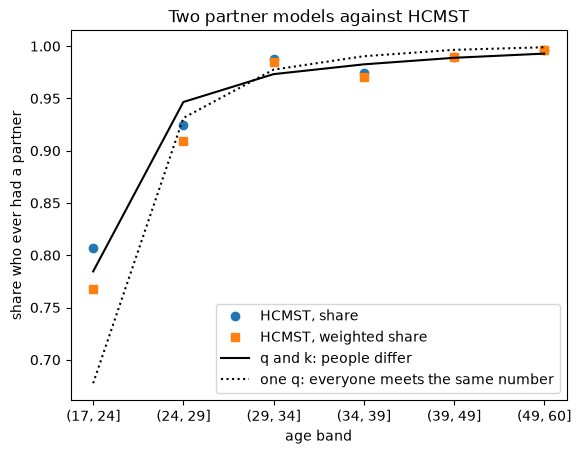

In [5]:
n = curve[hcmst["age"].to_numpy()]
by_band = lambda chance: pd.Series(chance.mean(axis=0)).groupby(bands.to_numpy(), observed=True).mean()
predicted = by_band(partner_chance(n[None, :], q[:, None], k[:, None]))
predicted_flat = by_band(1 - (1 - q_flat[:, None]) ** n[None, :])
labels = [str(b) for b in observed.index]
fig, ax = plt.subplots()
ax.plot(labels, observed["ever, share"], "o", label="HCMST, share")
ax.plot(labels, observed["ever, weighted share"], "s", label="HCMST, weighted share")
ax.plot(labels, predicted.values, "k-", label="q and k: people differ")
ax.plot(labels, predicted_flat.values, "k:", label="one q: everyone meets the same number")
ax.set(xlabel="age band", ylabel="share who ever had a partner", title="Two partner models against HCMST")
ax.legend()
pd.DataFrame({"observed": observed["ever, share"].values, "q and k": predicted.values,
              "one q": predicted_flat.values}, index=labels).round(3)

## Which model predicts better?

LOO (leave one out cross validation) scores how well each model predicts each person it did not see.
elpd is that score summed over people, and higher is better. `dse` is the standard error of the
difference.

In [6]:
az.compare({"q and k": match, "one q": flat})

,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
q and k,0,0.0,0.0,NaN,,,2.0,-330.0,26.0,0.89
one q,1,-10.0,6.2,0.98,,,1.3,-350.0,28.0,0.11


## How many of them could be the one?

The average person has talked to N(60) people of their own age by 60. A share q of them could have
become a partner.

In [7]:
possible = q * curve[60]
alone = 1 - partner_chance(curve[60], q, k)
print(f"1 in {1 / np.median(q):,.0f} of the people your age you talk to could be a partner")
print(f"possible partners met by 60: {np.median(possible):.0f}, 94% interval {np.percentile(possible, 3):.0f} to {np.percentile(possible, 97):.0f}")
print(f"share of people the model leaves without a partner by 60: {alone.mean():.1%}")

1 in 424 of the people your age you talk to could be a partner
possible partners met by 60: 14, 94% interval 10 to 19
share of people the model leaves without a partner by 60: 0.6%


## Known limits

1. The contact rates come from Europe between 2005 and 2012 and the partner data from the US in 2017.
2. The survey weights are not in the likelihood. The weighted shares are shown as a check.
3. N(a) is the curve of a typical country and is treated as known.
4. q is the same at every age.
5. "Ever had a partner" counts any past partner, so a short relationship counts the same as a life
   long one.
6. The model only counts people within 5 years of your age. In HCMST, 73% of couples are that close
   in age.
7. The diaries cannot see people who meet online. In HCMST, 37% of the couples who met in 2010 or
   later met online.